# Себестоимость, ABC/XYZ и динамика

**Цель:** Подготовить данные по себестоимости, объединить с выручкой, рассчитать ABC/XYZ по выручке и количеству, проанализировать сезонность, оборачиваемость запасов и динамику прибыли.

**Вход:** `Движение.xlsx`, `df_long_Выручка.xlsx` (не приложены).

**Основные шаги:** melt MultiIndex, merge, классификация ABC/XYZ, сводные таблицы, анализ сезонности и трендов.

**Навыки:** pandas, ABC/XYZ, агрегация временных рядов, seaborn/matplotlib.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.ticker as mticker

In [2]:
df = pd.read_excel('Движение.xlsx', header=[0, 1, 2])  # Читаем с многоуровневыми заголовками
df

Артикул                                       Номенклатура  \
      Unnamed: 0_level_1                                 Unnamed: 1_level_1   
      Unnamed: 0_level_2                                 Unnamed: 1_level_2   
0            0Т-00042714                10 300 500 H EVRA (269Вт) ПОД ЗАКАЗ   
1            0Т-00039061      10 500 1000 H  Royal Thermo (820Вт) ПОД ЗАКАЗ   
2            0Т-00042733               10 500 1000 H EVRA (835Вт) ПОД ЗАКАЗ   
3            0Т-00045841      10 500 1100 H  Royal Thermo (902Вт) ПОД ЗАКАЗ   
4            0Т-00041474      10 500 1200 H  Royal Thermo (984Вт) ПОД ЗАКАЗ   
...                  ...                                                ...   
15441        0Т-00032264  яяяяяяяяяяяя11 600х1200 CV Purmo (1539 вт 90/7...   
15442        0Т-00031084             яяяяяяяяяяяяОтвод 110/30 внут Политрон   
15443        0Т-00006458  яяяяяяяяяяяяяяяяяМанометр ТМ-510Р.05 16 кгс/см...   
15444        0Т-00031089  яяяяяяяяяяяяяяяяяОтвод 110/90 с вых. 50 прям. ...   
15445              Итого                                                NaN   

                Ед. изм.    Январь 2021 г.                           \
      Unnamed: 2_level_1 Начальный остаток                   Приход   
      Unnamed: 2_level_2        Количество Себестоимость Количество   
0                     шт              0.00          0.00          0   
1                     шт              0.00          0.00          0   
2                     шт              0.00          0.00          0   
3                     шт              0.00          0.00          0   
4                     шт              0.00          0.00          0   
...                  ...               ...           ...        ...   
15441                 шт              3.00      12231.63          0   
15442                 шт             82.00       2458.55          0   
15443                 шт              1.00          1.00          0   
15444                 шт             37.00       2645.37          0   
15445                NaN         393203.55   39012050.21     318692   

                                                               ...  \
                        Расход               Конечный остаток  ...   
      Себестоимость Количество Себестоимость       Количество  ...   
0              0.00          0          0.00             0.00  ...   
1              0.00          0          0.00             0.00  ...   
2              0.00          0          0.00             0.00  ...   
3              0.00          0          0.00             0.00  ...   
4              0.00          0          0.00             0.00  ...   
...             ...        ...           ...              ...  ...   
15441          0.00          0          0.00             3.00  ...   
15442          0.00         20        599.64            62.00  ...   
15443          0.00          0          0.00             1.00  ...   
15444          0.00         13        929.45            24.00  ...   
15445   25579536.11     203906   22686667.29        508118.55  ...   

          Март 2025 г.                           Итого                \
      Конечный остаток               Начальный остаток                 
            Количество Себестоимость        Количество Себестоимость   
0                 0.00           0.0              0.00          0.00   
1                 0.00           0.0              0.00          0.00   
2                 0.00           0.0              0.00          0.00   
3                 0.00           0.0              0.00          0.00   
4                 0.00           0.0              0.00          0.00   
...                ...           ...               ...           ...   
15441             0.00           0.0              3.00      12231.63   
15442             0.00           0.0             82.00       2458.55   
15443             0.00           0.0              1.00          1.00   
15444             0.00           0.0             37.00       2645.37  

In [3]:
# Удаляем последнюю строку с итогом
df = df.drop(df.tail(1).index)
# Удаляем столбцы, где первый уровень заголовков содержит "Итого"
df = df.loc[:, df.columns.get_level_values(0) != "Итого"]

In [4]:
# создаем df только с количеством
#df_amount = df.loc[:, df.columns.get_level_values(2) != "Себестоимость"] проблема с Апрелем 2022 года
#df_amount = df.loc[:, df.columns.get_level_values(2) == "Количество"] некорректно

df_amount = df.loc[:, 
    (df.columns.get_level_values(0).isin(["Артикул", "Номенклатура", "Ед. изм."])) |
    (df.columns.get_level_values(2) == "Себестоимость")
]

In [5]:
df_amount.columns.tolist()

[('Артикул', 'Unnamed: 0_level_1', 'Unnamed: 0_level_2'),
 ('Номенклатура', 'Unnamed: 1_level_1', 'Unnamed: 1_level_2'),
 ('Ед. изм.', 'Unnamed: 2_level_1', 'Unnamed: 2_level_2'),
 ('Январь 2021 г.', 'Начальный остаток', 'Себестоимость'),
 ('Январь 2021 г.', 'Приход', 'Себестоимость'),
 ('Январь 2021 г.', 'Расход', 'Себестоимость'),
 ('Январь 2021 г.', 'Конечный остаток', 'Себестоимость'),
 ('Февраль 2021 г.', 'Начальный остаток', 'Себестоимость'),
 ('Февраль 2021 г.', 'Приход', 'Себестоимость'),
 ('Февраль 2021 г.', 'Расход', 'Себестоимость'),
 ('Февраль 2021 г.', 'Конечный остаток', 'Себестоимость'),
 ('Март 2021 г.', 'Начальный остаток', 'Себестоимость'),
 ('Март 2021 г.', 'Приход', 'Себестоимость'),
 ('Март 2021 г.', 'Расход', 'Себестоимость'),
 ('Март 2021 г.', 'Конечный остаток', 'Себестоимость'),
 ('Апрель 2021 г.', 'Начальный остаток', 'Себестоимость'),
 ('Апрель 2021 г.', 'Приход', 'Себестоимость'),
 ('Апрель 2021 г.', 'Расход', 'Себестоимость'),
 ('Апрель 2021 г.', 'Конечный 

In [6]:
df_1 = df_amount.loc[:, 
    (df_amount.columns.get_level_values(0).isin(["Артикул", "Номенклатура", "Ед. изм."])) |
    (df_amount.columns.get_level_values(1) == "Начальный остаток")
]

df_2 = df_amount.loc[:, 
    (df_amount.columns.get_level_values(0).isin(["Артикул", "Номенклатура", "Ед. изм."])) |
    (df_amount.columns.get_level_values(1) == "Приход")
]

df_3 = df_amount.loc[:, 
    (df_amount.columns.get_level_values(0).isin(["Артикул", "Номенклатура", "Ед. изм."])) |
    (df_amount.columns.get_level_values(1) == "Расход")
]

df_4 = df_amount.loc[:, 
    (df_amount.columns.get_level_values(0).isin(["Артикул", "Номенклатура", "Ед. изм."])) |
    (df_amount.columns.get_level_values(1) == "Конечный остаток")
]

In [7]:
# df_1
df_1.columns = df_1.columns.droplevel(1)
df_1.columns = df_1.columns.droplevel(1)

# df_2
df_2.columns = df_2.columns.droplevel(1)
df_2.columns = df_2.columns.droplevel(1)

# df_3
df_3.columns = df_3.columns.droplevel(1)
df_3.columns = df_3.columns.droplevel(1)

# df_4
df_4.columns = df_4.columns.droplevel(1)
df_4.columns = df_4.columns.droplevel(1)

In [8]:
df_1_long = df_1.melt(id_vars=['Артикул', 'Номенклатура', 'Ед. изм.'], var_name='Дата', value_name='Начальный остаток')
df_2_long = df_2.melt(id_vars=['Артикул', 'Номенклатура', 'Ед. изм.'], var_name='Дата', value_name='Приход')
df_3_long = df_3.melt(id_vars=['Артикул', 'Номенклатура', 'Ед. изм.'], var_name='Дата', value_name='Расход')
df_4_long = df_4.melt(id_vars=['Артикул', 'Номенклатура', 'Ед. изм.'], var_name='Дата', value_name='Конечный остаток')

In [9]:
# Определяем общий столбец для объединения (например, ['Артикул', 'Номенклатура', 'Ед. изм.', 'Дата'])
common_columns = ['Артикул', 'Номенклатура', 'Ед. изм.', 'Дата']

# Объединяем все датасеты по этим столбцам
df_final = df_1_long.merge(df_2_long, on=common_columns, how="outer", suffixes=('', '_2'))\
                    .merge(df_3_long, on=common_columns, how="outer", suffixes=('', '_3'))\
                    .merge(df_4_long, on=common_columns, how="outer", suffixes=('', '_4'))
df_final.head()

,Артикул,Номенклатура,Ед. изм.,Дата,Начальный остаток,Приход,Расход,Конечный остаток
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2021 г.,20379.08,48774.81,56835.83,25834.47
1,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2022 г.,0.00,86530.76,86530.76,0.00
2,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2023 г.,0.00,30935.01,30935.01,0.00
3,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2024 г.,0.00,59738.32,59738.32,0.00
4,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Апрель 2021 г.,61571.85,7941.28,46342.08,23171.05


In [10]:
#df_final.isna().sum()
print(df_final.duplicated(subset=common_columns).sum())
print(df_1_long.duplicated(subset=common_columns).sum())

0
0


In [11]:
# Создаём словарь соответствий русских месяцев
months_dict = {
    "Январь": "01", "Февраль": "02", "Март": "03", "Апрель": "04",
    "Май": "05", "Июнь": "06", "Июль": "07", "Август": "08",
    "Сентябрь": "09", "Октябрь": "10", "Ноябрь": "11", "Декабрь": "12"
}

# Удаляем "г." и разбиваем строку на месяц и год
df_final["Дата"] = df_final["Дата"].str.replace(" г.", "", regex=False)
df_final["Месяц"] = df_final["Дата"].str.split(" ").str[0]
df_final["Год"] = df_final["Дата"].str.split(" ").str[1]

# Заменяем названия месяцев на числовой формат
df_final["Месяц"] = df_final["Месяц"].map(months_dict)

# Формируем новую дату в формате YYYY-MM-DD
df_final["Дата"] = pd.to_datetime(df_final["Год"] + "-" + df_final["Месяц"] + "-01")
df_final.drop(columns=["Месяц", "Год"], inplace=True)

In [12]:
df_final.columns = ['Код', 'Номенклатура', 'Ед_изм', 'Дата', 'Начальный_остаток','Приход', 'Расход', 'Конечный_остаток']

In [13]:
df_final

,Код,Номенклатура,Ед_изм,Дата,Начальный_остаток,Приход,Расход,Конечный_остаток
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-08-01,20379.08,48774.81,56835.83,25834.47
1,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2022-08-01,0.00,86530.76,86530.76,0.00
2,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2023-08-01,0.00,30935.01,30935.01,0.00
3,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2024-08-01,0.00,59738.32,59738.32,0.00
4,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-04-01,61571.85,7941.28,46342.08,23171.05
...,...,...,...,...,...,...,...,...
787690,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2021-01-01,211.72,175.00,64.45,322.27
787691,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2022-01-01,293.31,0.00,0.00,293.31
787692,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2023-01-01,244.84,0.00,104.93,139.91
787693,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2024-01-01,270.70,0.00,0.00,270.70


# Добавляем df ВЫРУЧКА

In [14]:
df_revenue = pd.read_excel('df_long_Выручка.xlsx') #723435
df_revenue.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 723435 entries, 0 to 723434
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Код           723435 non-null  object        
 1   Номенклатура  723435 non-null  object        
 2   Дата          723435 non-null  datetime64[ns]
 3   Выручка       723435 non-null  float64       
dtypes: datetime64[ns](1), float64(1), object(2)
memory usage: 22.1+ MB


In [15]:
df_revenue

,Код,Номенклатура,Дата,Выручка
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,2021-01-02,2287.96
1,00-00000029,Бак 1500 Combi W BW (сине-белый) для воды с по...,2021-01-02,0.00
2,00-00000030,Бак 1100 Combi W BW (сине-белый) для воды с по...,2021-01-02,0.00
3,00-00000054,я33 200х1400 RCV Purmo (1931 вт 90/70/20) ПОД...,2021-01-02,0.00
4,00-00000063,яШайба М 20 оцинк. усиленная ПОД ЗАКАЗ,2021-01-02,0.00
...,...,...,...,...
723430,0Т-00056173,яРеле давления LР/3 (датчик сухого хода) ПОД З...,2025-03-02,592.62
723431,0Т-00056196,Насосная станция SCA MINI с частотным преобраз...,2025-03-02,20715.00
723432,0Т-00056212,"яКлапан 3/4""x1""пред. для водоснабжения 6 бар ...",2025-03-02,445.48
723433,26108,яАмериканка 1/2 прямая латунь 151 Itap ПОД ЗАКАЗ,2025-03-02,0.00


In [16]:
# Заменяем день на 1 в датах df_revenue
df_revenue['Дата'] = df_revenue['Дата'].apply(lambda x: x.replace(day=1))

In [17]:
df_revenue['Код'].nunique()

14185

In [18]:
# Оставляем в df_final только те строки, у которых 'Код' есть в df_revenue
df_final = df_final[df_final['Код'].isin(df_revenue['Код'])]

# Объединяем df_final и df_revenue по 'Дата' и 'Код', добавляя только столбец 'Выручка'
df_final = df_final.merge(df_revenue[['Код', 'Дата', 'Выручка']], on=['Код', 'Дата'], how='left')

In [19]:
df_final

,Код,Номенклатура,Ед_изм,Дата,Начальный_остаток,Приход,Расход,Конечный_остаток,Выручка
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-08-01,20379.08,48774.81,56835.83,25834.47,75469.85
1,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2022-08-01,0.00,86530.76,86530.76,0.00,106442.65
2,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2023-08-01,0.00,30935.01,30935.01,0.00,38734.71
3,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2024-08-01,0.00,59738.32,59738.32,0.00,90496.00
4,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-04-01,61571.85,7941.28,46342.08,23171.05,57718.98
...,...,...,...,...,...,...,...,...,...
723430,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2021-01-01,211.72,175.00,64.45,322.27,89.88
723431,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2022-01-01,293.31,0.00,0.00,293.31,0.00
723432,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2023-01-01,244.84,0.00,104.93,139.91,172.06
723433,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2024-01-01,270.70,0.00,0.00,270.70,0.00


### Создание КАТЕГОРИЙ товаров ПОД ЗАКАЗ / СКЛАД / другое

In [20]:
"""
НЕ ПОСТАВЛЯЕТСЯ
не поставляется
НЕ ПОСТАВЛЯЕМ
НЕ ПОСТВЛСЯЮТСЯ
НЕ ПОСТ

УЦЕНКА
ПО ЗАПРОСУ
РАСПРОДАЖА
ДОПРОДАЕМ
ОБЪЕКТНЫЙ
ЛИКВИДАЦИЯ
ликвидация

СНЯТ С ПРОИЗВОДСТВА
СНЯТ С ПРОИЗВ
СНЯТ С ПРОИЗ
СНЯТ С ПР
СНЯТ
"""

'\nНЕ ПОСТАВЛЯЕТСЯ\nне поставляется\nНЕ ПОСТАВЛЯЕМ\nНЕ ПОСТВЛСЯЮТСЯ\nНЕ ПОСТ\n\nУЦЕНКА\nПО ЗАПРОСУ\nРАСПРОДАЖА\nДОПРОДАЕМ\nОБЪЕКТНЫЙ\nЛИКВИДАЦИЯ\nликвидация\n\nСНЯТ С ПРОИЗВОДСТВА\nСНЯТ С ПРОИЗВ\nСНЯТ С ПРОИЗ\nСНЯТ С ПР\nСНЯТ\n'

In [21]:
# Функция для присваивания категории
def assign_category(nomenklatura):
    if 'СКЛАД' in nomenklatura:
        return 1
    elif ('ПОД ЗАКАЗ' in nomenklatura or 'ПОД  ЗАКАЗ' in nomenklatura or 
          'ПОД ЗАКА' in nomenklatura or 'ПОД заказ' in nomenklatura or 
          'ПОД ЗАКЗА' in nomenklatura or 'ПОДЗАКАЗ' in nomenklatura or 
          'ПОД ЗАКА' in nomenklatura):
            return 2
    else:
        return 0

df_final['Категория'] = df_final['Номенклатура'].apply(assign_category)

In [22]:
# Извлекаем год из даты
df_final['Год'] = df_final['Дата'].dt.year

In [23]:
df_final.head()

,Код,Номенклатура,Ед_изм,Дата,Начальный_остаток,Приход,Расход,Конечный_остаток,Выручка,Категория,Год
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-08-01,20379.08,48774.81,56835.83,25834.47,75469.85,2,2021
1,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2022-08-01,0.00,86530.76,86530.76,0.00,106442.65,2,2022
2,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2023-08-01,0.00,30935.01,30935.01,0.00,38734.71,2,2023
3,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2024-08-01,0.00,59738.32,59738.32,0.00,90496.00,2,2024
4,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-04-01,61571.85,7941.28,46342.08,23171.05,57718.98,2,2021


### Датасет только СКЛАД

In [24]:
df_final_only_sklad = df_final[df_final['Категория'] == 1].sort_values(by=["Номенклатура", "Дата"]).reset_index(drop=True)

In [25]:
df_final_only_sklad['Номенклатура'].nunique()

2467

### Попытка найти ответ на вопрос: а были ли такие товары ПОД ЗАКАЗ, которые продавались в 2024 году в 5-6 месяцах?! не нужно ли их добавить в ассортимент СКЛАД и сравнение ВЫРУЧКИ

In [26]:
df_final.head(2)

,Код,Номенклатура,Ед_изм,Дата,Начальный_остаток,Приход,Расход,Конечный_остаток,Выручка,Категория,Год
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-08-01,20379.08,48774.81,56835.83,25834.47,75469.85,2,2021
1,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2022-08-01,0.00,86530.76,86530.76,0.00,106442.65,2,2022


In [27]:
df_non_null_sales_in_zakaz_2024 = df_final[(df_final['Категория'] == 2) & (df_final['Год'] == 2024) & (df_final['Расход'] > 0)].copy()

In [28]:
df_non_null_sales_in_zakaz_2024['Месяц'] = df_non_null_sales_in_zakaz_2024['Дата'].dt.month
# Группируем по товару (Код) и считаем количество уникальных месяцев с ненулевыми продажами за 2024 год
# это количество месяцев, в которых у ПОД ЗАКАЗ были ненулевые продажи за 2024
df_months_sales_2024 = df_non_null_sales_in_zakaz_2024.groupby(['Код', 'Номенклатура'])['Месяц'].nunique().reset_index()
df_months_sales_2024.rename(columns={'Месяц': 'Уникальные_месяцы_с_расходами'}, inplace=True)
df_months_sales_2024.head()

,Код,Номенклатура,Уникальные_месяцы_с_расходами
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,6
1,00-00000176,яРадиатор RC22 500х1400 (2551 вт 90/70/20) Pur...,1
2,00-00000265,Шкаф ШРВ-7 (1300х120-180х648-711) Wester ПО...,1
3,00-00000524,яПереход ПЭ/латунь НР 32*1'' ПОД ЗАКАЗ,1
4,00-00000676,"Комплект т/с вентиль угловой 1/2""+ головка т/с...",2


In [29]:
len(df_months_sales_2024['Номенклатура'].unique())

4043

In [30]:
print('Продавались > 3 из 12 месяцев товаров:', df_months_sales_2024[df_months_sales_2024['Уникальные_месяцы_с_расходами'] > 3]['Код'].count())
print('Продавались > 5 из 12 месяцев товаров:', df_months_sales_2024[df_months_sales_2024['Уникальные_месяцы_с_расходами'] >= 5]['Код'].count())
print('Продавались > 5-8 из 12 месяцев товаров:', df_months_sales_2024[(df_months_sales_2024['Уникальные_месяцы_с_расходами'] > 5) & (df_months_sales_2024['Уникальные_месяцы_с_расходами'] <= 8)]['Код'].count())
print('Продавались > 8 из 12 месяцев товаров:', df_months_sales_2024[df_months_sales_2024['Уникальные_месяцы_с_расходами'] > 8]['Код'].count())
print('Продавались в 12 из 12 месяцев товаров:', df_months_sales_2024[df_months_sales_2024['Уникальные_месяцы_с_расходами'] == 12]['Код'].count())

Продавались > 3 из 12 месяцев товаров: 512
Продавались > 5 из 12 месяцев товаров: 300
Продавались > 5-8 из 12 месяцев товаров: 153
Продавались > 8 из 12 месяцев товаров: 26
Продавались в 12 из 12 месяцев товаров: 1


In [31]:
df_months_sales_2024_f = df_final[df_final['Код'].isin(df_months_sales_2024[df_months_sales_2024['Уникальные_месяцы_с_расходами'] >= 5]['Код'])]

In [32]:
d = df_months_sales_2024_f[df_months_sales_2024_f['Год'] == 2024]['Выручка'].sum()
d

43262713.08

In [33]:
# какая выручка была в 2024 году в сумме
df_itog_revenue_year = df_final.groupby('Год')['Выручка'].sum().reset_index()
total_sum_revenue_2024 = df_itog_revenue_year[df_itog_revenue_year['Год'] == 2024]['Выручка'].iloc[0]
total_sum_revenue_2024

566872681.58

In [34]:
d/total_sum_revenue_2024

0.07631821833328996

***Это доля выручки от товаров, которые только под заказ, но продавались 5 и более раз за 2024 год, в общей выручке за 2024 год***

In [35]:
df_itog_revenue_year

,Год,Выручка
0,2021,4.625521e+08
1,2022,3.808872e+08
2,2023,4.386377e+08
3,2024,5.668727e+08
4,2025,1.284178e+08


In [36]:
df_months_sales_2024[df_months_sales_2024['Уникальные_месяцы_с_расходами'] > 5]

,Код,Номенклатура,Уникальные_месяцы_с_расходами
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,6
9,00-00001134,яОтвод 50/45 Синикон ПОД ЗАКАЗ,6
13,00-00001138,яТройник 50/50/45 Синикон ПОД ЗАКАЗ,6
30,00000117,Кран 1 н/н бабочка BASE Valtec ПОД ЗАКАЗ /РАС...,8
34,00000282,"Штуцер 20х3/4"" НР Valtec ПОД ЗАКАЗ/РАСПРОД...",10
...,...,...,...
3179,0Т-00050623,яДатчик протечки проводной WSP (3м.) GIDROLOCK...,6
3263,0Т-00051242,Опора 32 ППР серый РТП упак 240/40 шт ПОД ЗАКАЗ,8
3265,0Т-00051251,Кран 1 НГ бабочка MVI ПОД ЗАКАЗ,6
3305,0Т-00051407,Комплект для шумоизоляции канализационных труб...,6


Да, действительно, эти 179 товаров принесли довольно большую прибыль!!! Но они почему-то в категории под заказ, хотя продавались больше 5 раз за год (>=)

# ABC-анализ по всему времени
(и еще сделать отдельно по 2024 году)

In [37]:
# Шаг 1: Группировка по 'Код' или 'Номенклатура', расчет суммарной выручки для каждого элемента
df_sales = df_final.groupby(['Код'])['Выручка'].sum().reset_index()

# Шаг 2: Сортировка по выручке по убыванию
df_sales = df_sales.sort_values(by='Выручка', ascending=False)

# Шаг 3: Накопление суммы выручки и расчет кумулятивного процента
df_sales['Кумулятивная_сумма'] = df_sales['Выручка'].cumsum()
df_sales['Кумулятивный_процент'] = df_sales['Кумулятивная_сумма'] / df_sales['Выручка'].sum() * 100

# Шаг 4: Классификация элементов на A, B, C
def abc_classification(row):
    if row['Кумулятивный_процент'] <= 80:
        return 'A'
    elif row['Кумулятивный_процент'] <= 95:
        return 'B'
    else:
        return 'C'

df_sales['ABC_категория'] = df_sales.apply(abc_classification, axis=1)
# Объединяем результат ABC-анализа с df_final
df_final = df_final.merge(df_sales[['Код', 'ABC_категория']], on=['Код'], how='left')

In [38]:
# Считаем количество уникальных кодов в каждой категории ABC
unique_codes_in_abc = df_sales.groupby('ABC_категория')['Код'].nunique().reset_index()
unique_codes_in_abc.columns = ['ABC_категория', 'Количество уникальных кодов']
unique_codes_in_abc

,ABC_категория,Количество уникальных кодов
0,A,2136
1,B,3479
2,C,8570


In [39]:
# Фильтруем данные по 2024 году
df_2024 = df_final[df_final['Год'] == 2024]
# Шаг 1: Группировка по 'Код' и вычисление общей выручки для 2024 года
df_sales_2024 = df_2024.groupby(['Код'])['Выручка'].sum().reset_index()
# Шаг 2: Сортировка по выручке по убыванию
df_sales_2024 = df_sales_2024.sort_values(by='Выручка', ascending=False)
# Шаг 3: Накопление суммы выручки и расчет кумулятивного процента
df_sales_2024['Кумулятивная_сумма'] = df_sales_2024['Выручка'].cumsum()
df_sales_2024['Кумулятивный_процент'] = df_sales_2024['Кумулятивная_сумма'] / df_sales_2024['Выручка'].sum() * 100
df_sales_2024['ABC_2024'] = df_sales_2024.apply(abc_classification, axis=1)
# Шаг 5: Объединяем результат ABC-анализа с df_final
df_final = df_final.merge(df_sales_2024[['Код', 'ABC_2024']], on=['Код'], how='left')

In [40]:
unique_codes_in_abc_2024 = df_final.groupby('ABC_2024')['Код'].nunique().reset_index()
unique_codes_in_abc_2024.columns = ['ABC_2024', 'Количество уникальных кодов']
unique_codes_in_abc_2024

,ABC_2024,Количество уникальных кодов
0,A,1009
1,B,1633
2,C,11543


# XYZ-анализ по датасету с количеством

In [41]:
df_final_amount = pd.read_excel('df_final полный движение с категориями.xlsx')

In [42]:
df_final_amount = df_final_amount[df_final_amount['Код'].isin(df_revenue['Код'])]

### Расчет Коэффициентов вариации по 2023, 2024 и всем

In [43]:
df_sko_2023 = df_final_amount[df_final_amount['Год'] == 2023].groupby(['Код', 'Номенклатура', 'Ед_изм'])['Расход'].agg(['sum', 'std', 'mean']).reset_index()
df_sko_2024 = df_final_amount[df_final_amount['Год'] == 2024].groupby(['Код', 'Номенклатура', 'Ед_изм'])['Расход'].agg(['sum', 'std', 'mean']).reset_index()
df_sko_all = df_final_amount.groupby(['Код', 'Номенклатура', 'Ед_изм'])['Расход'].agg(['sum', 'std', 'mean']).reset_index()

df_sko_2023['КВ_2023'] = (df_sko_2023['std'] / df_sko_2023['mean']) * 100
df_sko_2024['КВ_2024'] = (df_sko_2024['std'] / df_sko_2024['mean']) * 100
df_sko_all['КВ_все'] = (df_sko_all['std'] / df_sko_all['mean']) * 100

In [44]:
# Функция для классификации на основе квартилей (немного под вопросом, у гпт <= вместо <)
def xyz_classification_by_quantile(cv_value, q1, q2):
    if cv_value < q1:  # Группа X: меньше первого квартиля
        return 'X'
    elif cv_value < q2:  # Группа Y: между первым и вторым квартилем
        return 'Y'
    else:  # Группа Z: больше второго квартиля
        return 'Z'

# Для каждого датафрейма находим квартили для соответствующего столбца
q1_2023, q2_2023, q3_2023 = df_sko_2023['КВ_2023'].quantile([0.25, 0.5, 0.75])
q1_2024, q2_2024, q3_2024 = df_sko_2024['КВ_2024'].quantile([0.25, 0.5, 0.75])
q1_all, q2_all, q3_all = df_sko_all['КВ_все'].quantile([0.25, 0.5, 0.75])

# Применяем функцию классификации на основе квартилей
df_sko_2023['XYZ_2023'] = df_sko_2023['КВ_2023'].apply(xyz_classification_by_quantile, args=(q1_2023, q2_2023))
df_sko_2024['XYZ_2024'] = df_sko_2024['КВ_2024'].apply(xyz_classification_by_quantile, args=(q1_2024, q2_2024))
df_sko_all['XYZ_all'] = df_sko_all['КВ_все'].apply(xyz_classification_by_quantile, args=(q1_all, q2_all))

### При необходимости добавить 2023 год

In [45]:
# Объединяем df_final с df_sko_2023 по столбцу 'Код', добавляя XYZ_2023
#df_final = df_final.merge(df_sko_2023[['Код', 'XYZ_2023']], on='Код', how='left')
# Объединяем df_final с df_sko_2024 по столбцу 'Код', добавляя XYZ_2024
df_final = df_final.merge(df_sko_2024[['Код', 'XYZ_2024']], on='Код', how='left')
# Объединяем df_final с df_sko_all по столбцу 'Код', добавляя XYZ_all
df_final = df_final.merge(df_sko_all[['Код', 'XYZ_all']], on='Код', how='left')

In [46]:
# Считаем количество уникальных кодов в каждой категории XYZ
unique_codes_in_xyz_2024 = df_sko_2024.groupby('XYZ_2024')['Код'].nunique().reset_index()
unique_codes_in_xyz_2024.columns = ['XYZ_2024', 'Количество уникальных кодов']
unique_codes_in_xyz_2024

,XYZ_2024,Количество уникальных кодов
0,X,1714
1,Y,1714
2,Z,10757


In [47]:
unique_codes_in_xyz_allt = df_sko_all.groupby('XYZ_all')['Код'].nunique().reset_index()
unique_codes_in_xyz_allt.columns = ['XYZ_all', 'Количество уникальных кодов']
unique_codes_in_xyz_allt

,XYZ_all,Количество уникальных кодов
0,X,3545
1,Y,3545
2,Z,7095


In [48]:
df_final

,Код,Номенклатура,Ед_изм,Дата,Начальный_остаток,Приход,Расход,Конечный_остаток,Выручка,Категория,Год,ABC_категория,ABC_2024,XYZ_2024,XYZ_all
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-08-01,20379.08,48774.81,56835.83,25834.47,75469.85,2,2021,A,A,X,X
1,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2022-08-01,0.00,86530.76,86530.76,0.00,106442.65,2,2022,A,A,X,X
2,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2023-08-01,0.00,30935.01,30935.01,0.00,38734.71,2,2023,A,A,X,X
3,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2024-08-01,0.00,59738.32,59738.32,0.00,90496.00,2,2024,A,A,X,X
4,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-04-01,61571.85,7941.28,46342.08,23171.05,57718.98,2,2021,A,A,X,X
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
723430,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2021-01-01,211.72,175.00,64.45,322.27,89.88,1,2021,C,C,Y,X
723431,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2022-01-01,293.31,0.00,0.00,293.31,0.00,1,2022,C,C,Y,X
723432,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2023-01-01,244.84,0.00,104.93,139.91,172.06,1,2023,C,C,Y,X
723433,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2024-01-01,270.70,0.00,0.00,270.70,0.00,1,2024,C,C,Y,X


# ABC-XYZ-анализ

In [49]:
df_final.columns

Index(['Код', 'Номенклатура', 'Ед_изм', 'Дата', 'Начальный_остаток', 'Приход',
       'Расход', 'Конечный_остаток', 'Выручка', 'Категория', 'Год',
       'ABC_категория', 'ABC_2024', 'XYZ_2024', 'XYZ_all'],
      dtype='object')

In [50]:
total_assortement = df_final['Код'].nunique()
# Рассчитываем доли
percentage_A = df_final[df_final['ABC_категория'] == 'A']['Код'].nunique() / total_assortement
percentage_B = df_final[df_final['ABC_категория'] == 'B']['Код'].nunique() / total_assortement
percentage_C = df_final[df_final['ABC_категория'] == 'C']['Код'].nunique() / total_assortement

print('Всего ассортимент:', total_assortement)
print(f'Доля товаров, которые приносит 80% выручки во всем ассортименте: {percentage_A:.2f}')
print(f'Доля товаров, которые имеют умеренное значение и приносит около 15% выручки: {percentage_B:.2f}')
print(f'Доля товаров, которые вносят минимальный вклад в общий результат (5% выручки): {percentage_C:.2f}')

Всего ассортимент: 14185
Доля товаров, которые приносит 80% выручки во всем ассортименте: 0.15
Доля товаров, которые имеют умеренное значение и приносит около 15% выручки: 0.25
Доля товаров, которые вносят минимальный вклад в общий результат (5% выручки): 0.60


In [51]:
# какой ассортимент был в 2024 году? то есть нужно посчитать сколько было позиций с ненулевым начальным остатком в 2024 году:
df_final_2024 = df_final[df_final['Год'] == 2024]
df_non_nul_2024 = df_final_2024[(df_final_2024['Начальный_остаток'] > 0) | (df_final_2024['Приход'] > 0) | (df_final_2024['Расход'] > 0)]

In [52]:
total_assortement_2024 = df_non_nul_2024['Код'].nunique()

percentage_A = df_non_nul_2024[df_non_nul_2024['ABC_2024'] == 'A']['Код'].nunique() / total_assortement_2024
percentage_B = df_non_nul_2024[df_non_nul_2024['ABC_2024'] == 'B']['Код'].nunique() / total_assortement_2024
percentage_C = df_non_nul_2024[df_non_nul_2024['ABC_2024'] == 'C']['Код'].nunique() / total_assortement_2024

print('Всего ассортимент в 2024 году:', total_assortement_2024)
print(f'Доля товаров, которые приносит 80% выручки в ассортименте в 2024 году: {percentage_A:.2f}')
print(f'Доля товаров, которые имеют умеренное значение и приносит около 15% выручки: {percentage_B:.2f}')
print(f'Доля товаров, которые вносят минимальный вклад в общий результат (5% выручки): {percentage_C:.2f}')

Всего ассортимент в 2024 году: 7383
Доля товаров, которые приносит 80% выручки в ассортименте в 2024 году: 0.14
Доля товаров, которые имеют умеренное значение и приносит около 15% выручки: 0.22
Доля товаров, которые вносят минимальный вклад в общий результат (5% выручки): 0.64


In [53]:
df_non_nul_2024_A = df_non_nul_2024[df_non_nul_2024['ABC_2024'] == 'A']
df_non_nul_2024_B = df_non_nul_2024[df_non_nul_2024['ABC_2024'] == 'B']
df_non_nul_2024_C = df_non_nul_2024[df_non_nul_2024['ABC_2024'] == 'C']

df_sclad_A = df_non_nul_2024_A[df_non_nul_2024_A['Категория'] == 1]['Номенклатура'].nunique()
df_sclad_B = df_non_nul_2024_B[df_non_nul_2024_B['Категория'] == 1]['Номенклатура'].nunique()
df_sclad_C = df_non_nul_2024_C[df_non_nul_2024_C['Категория'] == 1]['Номенклатура'].nunique()
print(f'Уникальных значений по категориям среди складских в 2024 году: A={df_sclad_A}, B={df_sclad_B}, C={df_sclad_C}')

Уникальных значений по категориям среди складских в 2024 году: A=492, B=649, C=1217


In [54]:
df_non_nul_2024

,Код,Номенклатура,Ед_изм,Дата,Начальный_остаток,Приход,Расход,Конечный_остаток,Выручка,Категория,Год,ABC_категория,ABC_2024,XYZ_2024,XYZ_all
3,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2024-08-01,0.00,59738.32,59738.32,0.00,90496.00,2,2024,A,A,X,X
15,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2024-07-01,0.00,20113.73,20113.73,0.00,30930.30,2,2024,A,A,X,X
27,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2024-03-01,0.00,92804.82,92804.82,0.00,103084.30,2,2024,A,A,X,X
36,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2024-10-01,0.00,41816.65,41816.65,0.00,56590.16,2,2024,A,A,X,X
44,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2024-02-01,0.00,37121.54,37121.54,0.00,53104.03,2,2024,A,A,X,X
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
723416,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2024-11-01,413.10,0.00,0.00,413.10,0.00,1,2024,C,C,Y,X
723420,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2024-10-01,568.19,0.00,155.09,413.10,0.00,1,2024,C,C,Y,X
723424,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2024-09-01,516.98,51.21,0.00,568.19,0.00,1,2024,C,C,Y,X
723428,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2024-02-01,270.70,0.00,108.28,162.42,0.00,1,2024,C,C,Y,X


In [55]:
# Оставим только нужные столбцы и удалим дубликаты по 'Код', 'ABC_2024', 'XYZ_2024'
unique_codes_2024 = df_final[['Код', 'ABC_2024', 'XYZ_2024']].drop_duplicates().reset_index(drop=True)

abc_xyz_matrix_2024 = unique_codes_2024.pivot_table(index='ABC_2024',
                                          columns='XYZ_2024',
                                          values='Код',
                                          aggfunc='nunique',
                                          fill_value=0)
abc_xyz_matrix_2024

XYZ_2024,X,Y,Z
ABC_2024,,,
A,467,221,321
B,563,414,656
C,684,1079,9780


In [56]:
# по всему периоду
unique_codes = df_final[['Код', 'ABC_категория', 'XYZ_all']].drop_duplicates().reset_index(drop=True)

abc_xyz_matrix = unique_codes.pivot_table(index='ABC_категория',
                                          columns='XYZ_all',
                                          values='Код',
                                          aggfunc='nunique',
                                          fill_value=0)
abc_xyz_matrix

XYZ_all,X,Y,Z
ABC_категория,,,
A,1224,370,542
B,1214,917,1348
C,1107,2258,5205


Вот здесь видно, что очень много товаров, которые СКЛАД из категории C (то есть они не приносят много прибыли)

XYZ_2024    X            Y               Z           
Категория   0    1   2   0    1    2     0    1     2
ABC_2024                                             
A          15  416  36  17   65  139    33   11   277
B           7  489  67  34  120  260    55   40   561
C          11  589  84  80  392  607  1841  345  7594


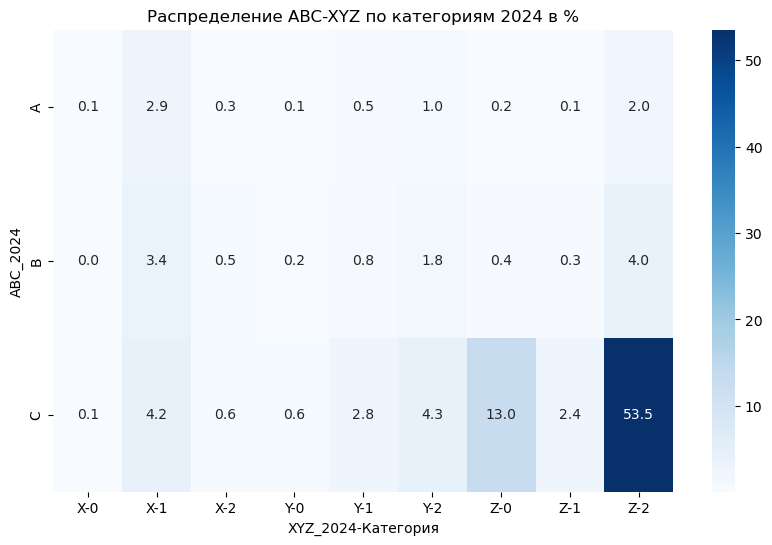

In [57]:
pivot = df_final.pivot_table(
    index='ABC_2024', 
    columns=['XYZ_2024', 'Категория'], 
    values='Код', 
    aggfunc=pd.Series.nunique, 
    fill_value=0
)
total_sum = pivot.sum().sum()
pivot_percent = (pivot / total_sum) * 100

# Выводим результат
print(pivot)


plt.figure(figsize=(10, 6))
#sns.heatmap(pivot_percent, annot=True, fmt='d', cmap="Blues")
sns.heatmap(pivot_percent, annot=True, fmt=".1f", cmap="Blues")
plt.title("Распределение ABC-XYZ по категориям 2024 в %")
plt.show()

XYZ_2024          X                             Y                      \
Категория         0         1         2         0         1         2   
ABC_2024                                                                
A          0.105746  2.932675  0.253789  0.119845  0.458231  0.979908   
B          0.049348  3.447303  0.472330  0.239690  0.845964  1.832922   
C          0.077547  4.152274  0.592175  0.563976  2.763483  4.279168   

XYZ_2024           Z                       
Категория          0         1          2  
ABC_2024                                   
A           0.232640  0.077547   1.952767  
B           0.387734  0.281988   3.954882  
C          12.978498  2.432147  53.535425  


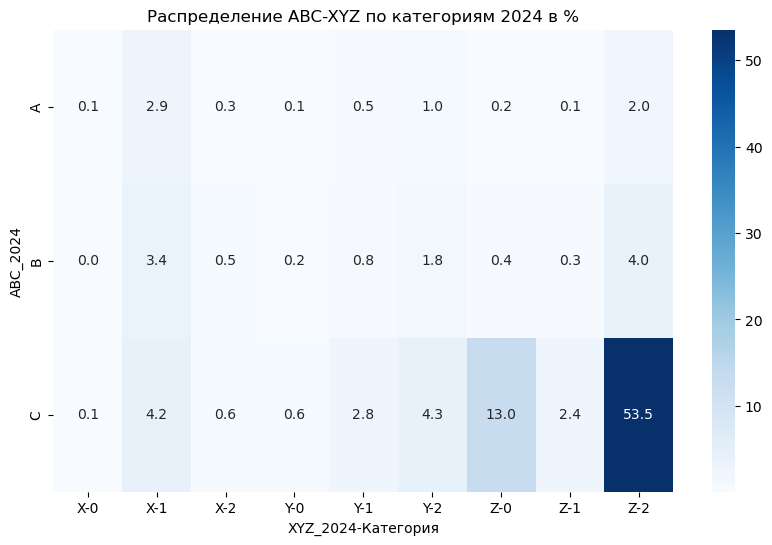

In [58]:
pivot = df_final.pivot_table(
    index='ABC_2024', 
    columns=['XYZ_2024', 'Категория'], 
    values='Код', 
    aggfunc=pd.Series.nunique, 
    fill_value=0
)
total_sum = pivot.sum().sum()
pivot_percent = (pivot / total_sum) * 100

# Выводим результат
print(pivot_percent)


plt.figure(figsize=(10, 6))
#sns.heatmap(pivot_percent, annot=True, fmt='d', cmap="Blues")
sns.heatmap(pivot_percent, annot=True, fmt=".1f", cmap="Blues")
plt.title("Распределение ABC-XYZ по категориям 2024 в %")
plt.show()

XYZ_all          X              Y               Z           
Категория        0    1    2    0    1     2    0    1     2
ABC_категория                                               
A              123  793  308   41   22   307   54    3   485
B              126  674  414  136   63   718  213   14  1121
C              112  557  438  375  212  1671  913  129  4163


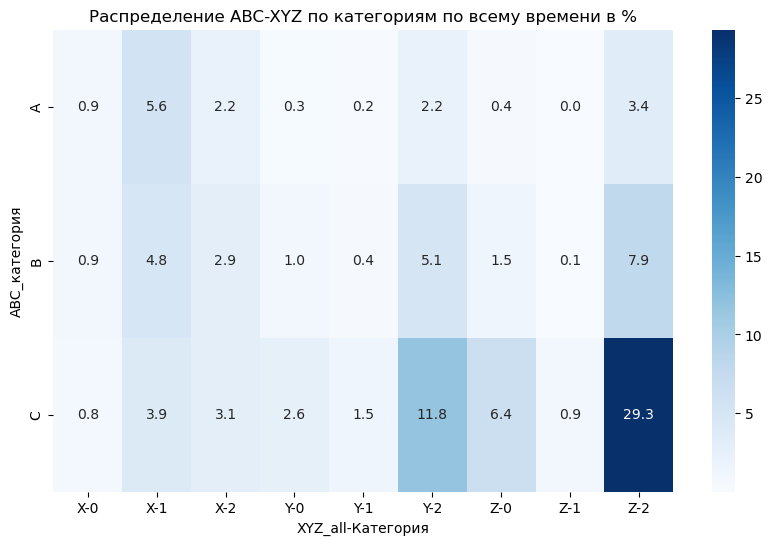

In [59]:
#
pivot = df_final.pivot_table(
    index='ABC_категория', 
    columns=['XYZ_all', 'Категория'], 
    values='Код', 
    aggfunc=pd.Series.nunique, 
    fill_value=0
)

total_sum = pivot.sum().sum()
pivot_percent = (pivot / total_sum) * 100

# Выводим результат
print(pivot)


plt.figure(figsize=(10, 6))
#sns.heatmap(pivot_percent, annot=True, fmt='d', cmap="Blues")
sns.heatmap(pivot_percent, annot=True, fmt=".1f", cmap="Blues")
plt.title("Распределение ABC-XYZ по категориям по всему времени в %")
plt.show()

# ТОЛЬКО СКЛАДСКИЕ и доли от общего кол-ва складских

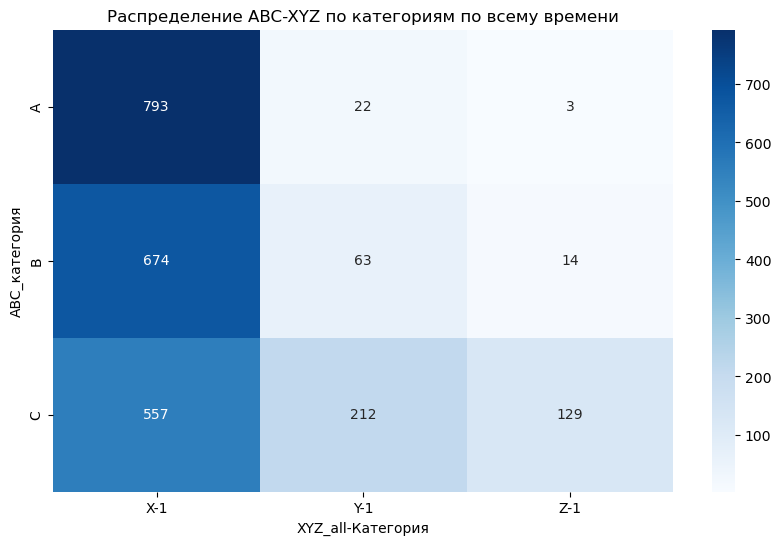

In [60]:
df_final_only_sclad = df_final[df_final['Категория'] == 1]

pivot = df_final_only_sclad.pivot_table(
    index='ABC_категория', 
    columns=['XYZ_all', 'Категория'], 
    values='Код', 
    aggfunc=pd.Series.nunique, 
    fill_value=0
)

plt.figure(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt='d', cmap="Blues")
plt.title("Распределение ABC-XYZ по категориям по всему времени")
plt.show()

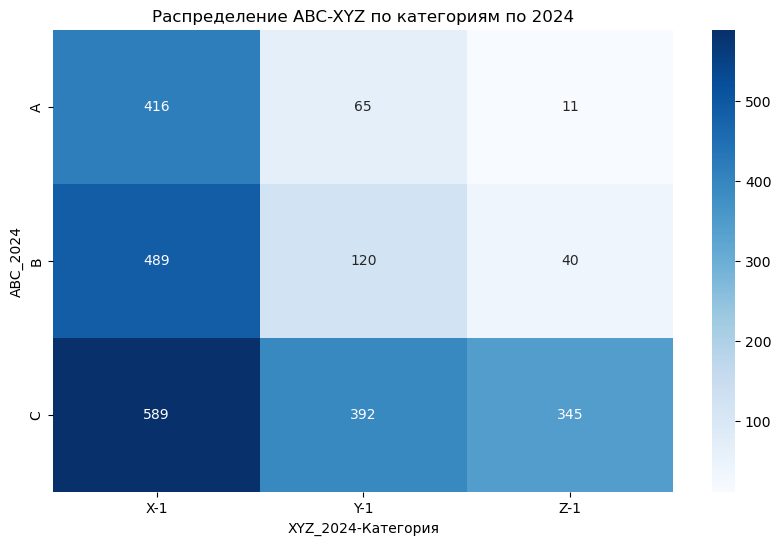

In [61]:
df_final_only_sclad = df_final[df_final['Категория'] == 1]

pivot = df_final_only_sclad.pivot_table(
    index='ABC_2024', 
    columns=['XYZ_2024', 'Категория'], 
    values='Код', 
    aggfunc=pd.Series.nunique, 
    fill_value=0
)

plt.figure(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt='d', cmap="Blues")
plt.title("Распределение ABC-XYZ по категориям по 2024")
plt.show()

XYZ_2024           X          Y          Z
Категория          1          1          1
ABC_2024                                  
A          16.862586   2.634779   0.445886
B          19.821646   4.864208   1.621403
C          23.875152  15.889745  13.984597


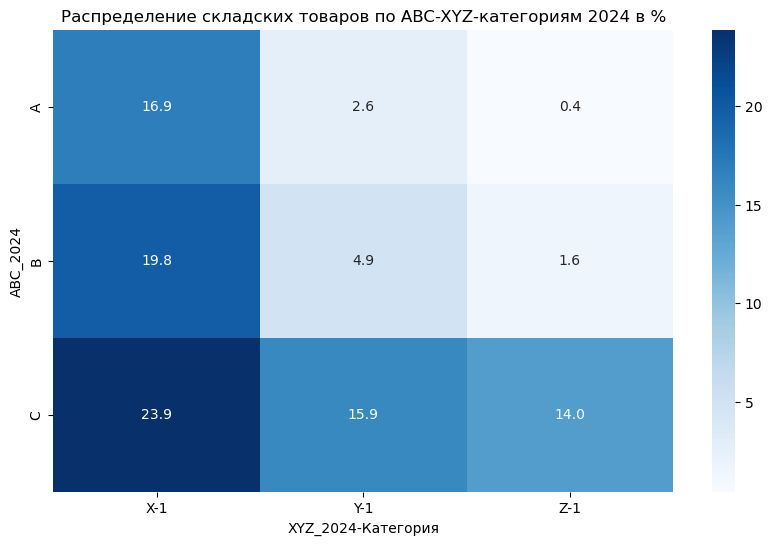

In [62]:
df_final_only_sclad = df_final[df_final['Категория'] == 1]

pivot = df_final_only_sclad.pivot_table(
    index='ABC_2024', 
    columns=['XYZ_2024', 'Категория'], 
    values='Код', 
    aggfunc=pd.Series.nunique, 
    fill_value=0
)

total_sum = pivot.sum().sum()
pivot_percent = (pivot / total_sum) * 100

# Выводим результат
print(pivot_percent)


plt.figure(figsize=(10, 6))
#sns.heatmap(pivot_percent, annot=True, fmt='d', cmap="Blues")
sns.heatmap(pivot_percent, annot=True, fmt=".1f", cmap="Blues")
plt.title("Распределение складских товаров по ABC-XYZ-категориям 2024 в %")
plt.show()

### А сколько товаров вообще продавалось компанией по каждому году? 
по каждому товару сумма расхода за год => должна быть больше 0

# Оборот / Коэффициент оборачиваемости по себестоимости
### Чтобы получить коэф надо ['Расход'] / ['Средний_остаток']

In [63]:
# Для каждой катгории итоговые дф
df_sklad_itog = df_final[df_final['Категория'] == 1].groupby('Дата')[['Начальный_остаток', 'Приход', 'Расход', 'Конечный_остаток', 'Выручка']].sum().reset_index()
df_zakaz_itog = df_final[df_final['Категория'] == 2].groupby('Дата')[['Начальный_остаток', 'Приход', 'Расход', 'Конечный_остаток', 'Выручка']].sum().reset_index()
df_itog = df_final.groupby('Дата')[['Начальный_остаток', 'Приход', 'Расход', 'Конечный_остаток', 'Выручка']].sum().reset_index()

In [64]:
df_sklad_itog['Год'] = df_sklad_itog['Дата'].dt.year
df_zakaz_itog['Год'] = df_zakaz_itog['Дата'].dt.year
df_itog['Год'] = df_itog['Дата'].dt.year

df_sklad_itog['Месяц'] = df_sklad_itog['Дата'].dt.month
df_zakaz_itog['Месяц'] = df_zakaz_itog['Дата'].dt.month
df_itog['Месяц'] = df_itog['Дата'].dt.month

In [65]:
# Добавляем расчет среднего остатка
df_itog['Средний_остаток'] = (df_itog['Начальный_остаток'] + df_itog['Конечный_остаток']) / 2
# Рассчитываем коэффициент оборачиваемости
df_itog['Коэф_оборачиваемости'] = (df_itog['Средний_остаток'] / df_itog['Расход']) * 30
# Заменяем возможные деления на 0 (если средний остаток = 0, то коэффициент = 0)
df_itog['Коэф_оборачиваемости'] = df_itog['Коэф_оборачиваемости'].fillna(0)

In [66]:
# Для СКЛАДА И ЗАКАЗА
df_sklad_itog['Средний_остаток'] = (df_sklad_itog['Начальный_остаток'] + df_sklad_itog['Конечный_остаток']) / 2
df_sklad_itog['Коэф_оборачиваемости'] = (df_sklad_itog['Средний_остаток'] / df_sklad_itog['Расход']) * 30
df_sklad_itog['Коэф_оборачиваемости'] = df_sklad_itog['Коэф_оборачиваемости'].fillna(0)

df_zakaz_itog['Средний_остаток'] = (df_zakaz_itog['Начальный_остаток'] + df_zakaz_itog['Конечный_остаток']) / 2
df_zakaz_itog['Коэф_оборачиваемости'] = (df_zakaz_itog['Средний_остаток'] / df_zakaz_itog['Расход']) * 30
df_zakaz_itog['Коэф_оборачиваемости'] = df_zakaz_itog['Коэф_оборачиваемости'].fillna(0)

In [67]:
print('ИТОГ КО', df_itog['Коэф_оборачиваемости'].describe())
print('СКЛАД КО', df_sklad_itog['Коэф_оборачиваемости'].describe())
print('ЗАКАЗ КО', df_zakaz_itog['Коэф_оборачиваемости'].describe())

ИТОГ КО count    51.000000
mean     29.151747
std       8.224275
min      18.372377
25%      22.903926
50%      28.066080
75%      32.230332
max      50.961835
Name: Коэф_оборачиваемости, dtype: float64
СКЛАД КО count    51.000000
mean     32.463106
std       9.733503
min      19.299719
25%      27.067747
50%      30.685049
75%      34.782828
max      71.040946
Name: Коэф_оборачиваемости, dtype: float64
ЗАКАЗ КО count    51.000000
mean     23.021688
std       8.568740
min       8.577708
25%      16.589130
50%      22.078617
75%      27.926341
max      45.654181
Name: Коэф_оборачиваемости, dtype: float64


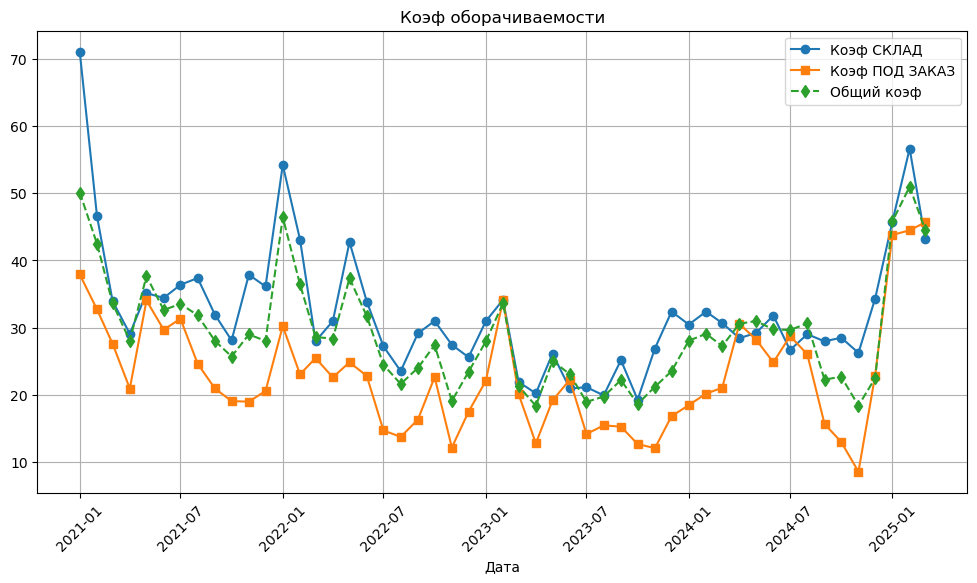

In [68]:
plt.figure(figsize=(12, 6))

# Рисуем линии
plt.plot(df_sklad_itog['Дата'], df_sklad_itog['Коэф_оборачиваемости'], label='Коэф СКЛАД', marker='o')
plt.plot(df_zakaz_itog['Дата'], df_zakaz_itog['Коэф_оборачиваемости'], label='Коэф ПОД ЗАКАЗ', marker='s')
plt.plot(df_itog['Дата'], df_itog['Коэф_оборачиваемости'], label='Общий коэф', marker='d', linestyle='--')

# Добавляем подписи
plt.xlabel('Дата')
#plt.ylabel('Расход')
plt.title('Коэф оборачиваемости')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

In [69]:
df_itog.to_excel('df_itog_выручка.xlsx', index=False)

C:\Users\Liza\AppData\Local\Temp\ipykernel_5728\1027480962.py:1: UserWarning: Pandas requires version '3.0.5' or newer of 'xlsxwriter' (version '3.0.3' currently installed).
  df_itog.to_excel('df_itog_выручка.xlsx', index=False)


In [70]:
df_all_itog_year = df_final.groupby('Год')[['Начальный_остаток', 'Приход', 'Расход', 'Конечный_остаток', 'Выручка']].sum().reset_index()

In [71]:
df_all_itog_year = df_all_itog_year[df_all_itog_year['Год'] != 2025]

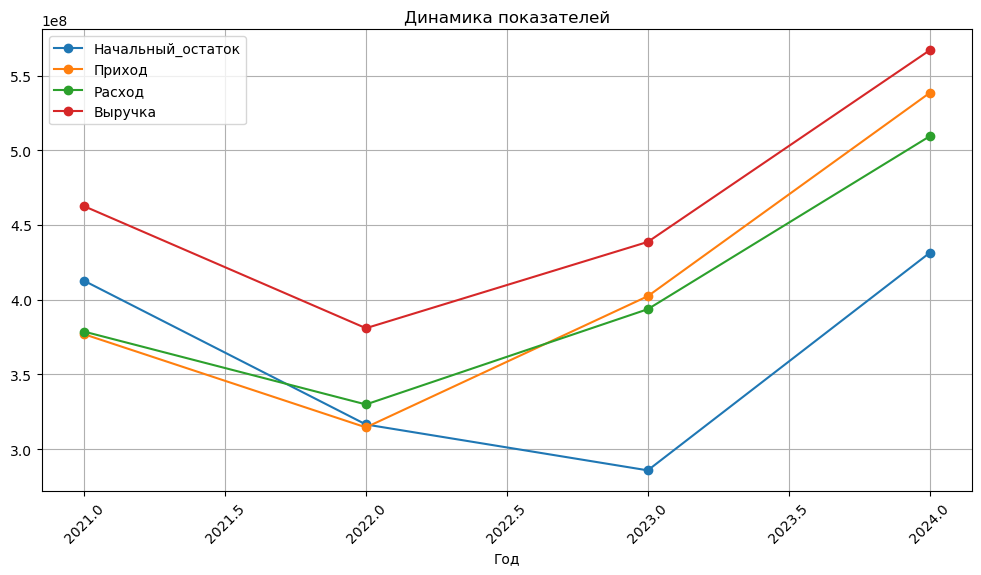

In [72]:
plt.figure(figsize=(12, 6))
# Рисуем линии
plt.plot(df_all_itog_year['Год'], df_all_itog_year['Начальный_остаток'], label='Начальный_остаток', marker='o')
plt.plot(df_all_itog_year['Год'], df_all_itog_year['Приход'], label='Приход', marker='o')
plt.plot(df_all_itog_year['Год'], df_all_itog_year['Расход'], label='Расход', marker='o')
plt.plot(df_all_itog_year['Год'], df_all_itog_year['Выручка'], label='Выручка', marker='o')

# Добавляем подписи
plt.xlabel('Год')
#plt.ylabel('Расход')
plt.title('Динамика показателей')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

In [73]:
df_final[df_final['Категория'] == 1]['Номенклатура'].nunique() / 14185

0.17391610856538597

In [74]:
df_final[df_final['Категория'] == 2]['Номенклатура'].nunique() / 14185

0.6785336623193514

In [75]:
df_final[df_final['Категория'] == 0]['Номенклатура'].nunique() / 14185

0.1475502291152626

In [76]:
df_final['Категория'].unique()

array([2, 0, 1], dtype=int64)

# Вычисление коэффициента сезонности с ГПТ

In [77]:
df_final.columns

Index(['Код', 'Номенклатура', 'Ед_изм', 'Дата', 'Начальный_остаток', 'Приход',
       'Расход', 'Конечный_остаток', 'Выручка', 'Категория', 'Год',
       'ABC_категория', 'ABC_2024', 'XYZ_2024', 'XYZ_all'],
      dtype='object')

In [78]:
df_final['Месяц'] = df_final['Дата'].dt.month

In [79]:
# Средняя выручка по каждому месяцу
month_avg = df_final.groupby('Месяц')['Выручка'].mean()
overall_avg = df_final['Выручка'].mean()
seasonality = month_avg / overall_avg
seasonality = seasonality.round(3)
print(seasonality)

Месяц
1     0.779
2     0.816
3     0.994
4     0.972
5     0.855
6     0.984
7     1.025
8     1.048
9     1.114
10    1.154
11    1.242
12    1.122
Name: Выручка, dtype: float64


# ПРИБЫЛЬ СТОЛБИКОВАЯ

In [80]:
df_final

,Код,Номенклатура,Ед_изм,Дата,Начальный_остаток,Приход,Расход,Конечный_остаток,Выручка,Категория,Год,ABC_категория,ABC_2024,XYZ_2024,XYZ_all,Месяц
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-08-01,20379.08,48774.81,56835.83,25834.47,75469.85,2,2021,A,A,X,X,8
1,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2022-08-01,0.00,86530.76,86530.76,0.00,106442.65,2,2022,A,A,X,X,8
2,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2023-08-01,0.00,30935.01,30935.01,0.00,38734.71,2,2023,A,A,X,X,8
3,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2024-08-01,0.00,59738.32,59738.32,0.00,90496.00,2,2024,A,A,X,X,8
4,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-04-01,61571.85,7941.28,46342.08,23171.05,57718.98,2,2021,A,A,X,X,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
723430,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2021-01-01,211.72,175.00,64.45,322.27,89.88,1,2021,C,C,Y,X,1
723431,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2022-01-01,293.31,0.00,0.00,293.31,0.00,1,2022,C,C,Y,X,1
723432,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2023-01-01,244.84,0.00,104.93,139.91,172.06,1,2023,C,C,Y,X,1
723433,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2024-01-01,270.70,0.00,0.00,270.70,0.00,1,2024,C,C,Y,X,1


In [81]:
df_final['МП'] = df_final['Выручка'] - df_final['Расход']

In [110]:
df_filtered = df_final[df_final['Год'] < 2025]

# Группировка по годам
mounth_expense = df_filtered.groupby('Дата')['МП'].sum().reset_index()

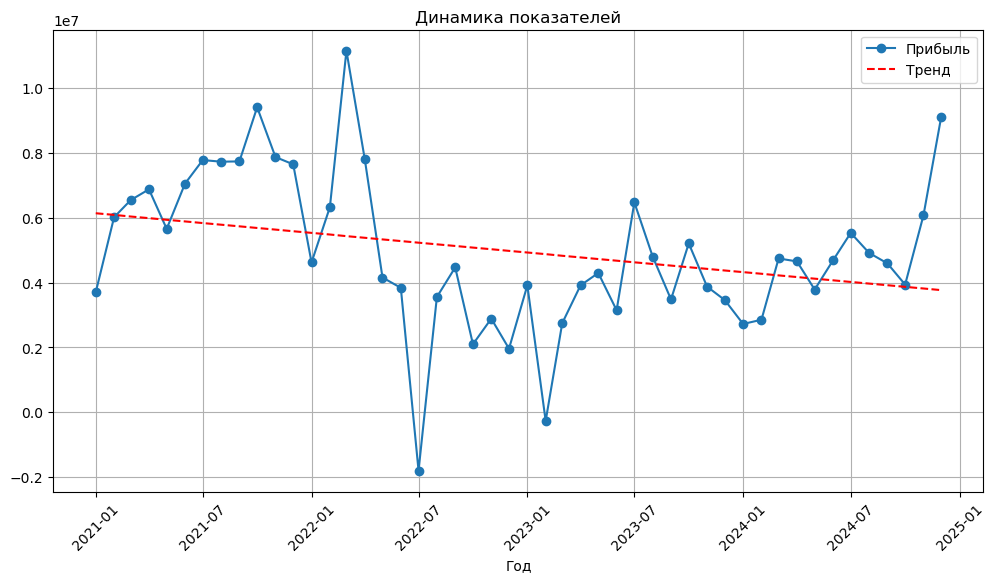

In [113]:
from sklearn.linear_model import LinearRegression

plt.figure(figsize=(12, 6))

# Ось X в числовом формате для тренда
x = np.arange(len(mounth_expense))
y = mounth_expense['МП'].values

# Модель линейной регрессии
model = LinearRegression()
model.fit(x.reshape(-1, 1), y)
trend = model.predict(x.reshape(-1, 1))

# Построение графика
plt.plot(mounth_expense['Дата'], mounth_expense['МП'], label='Прибыль', marker='o')
plt.plot(mounth_expense['Дата'], trend, color='red', linestyle='--', label='Тренд')

# Подписи и оформление
plt.xlabel('Год')
plt.title('Динамика показателей')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)

plt.show()


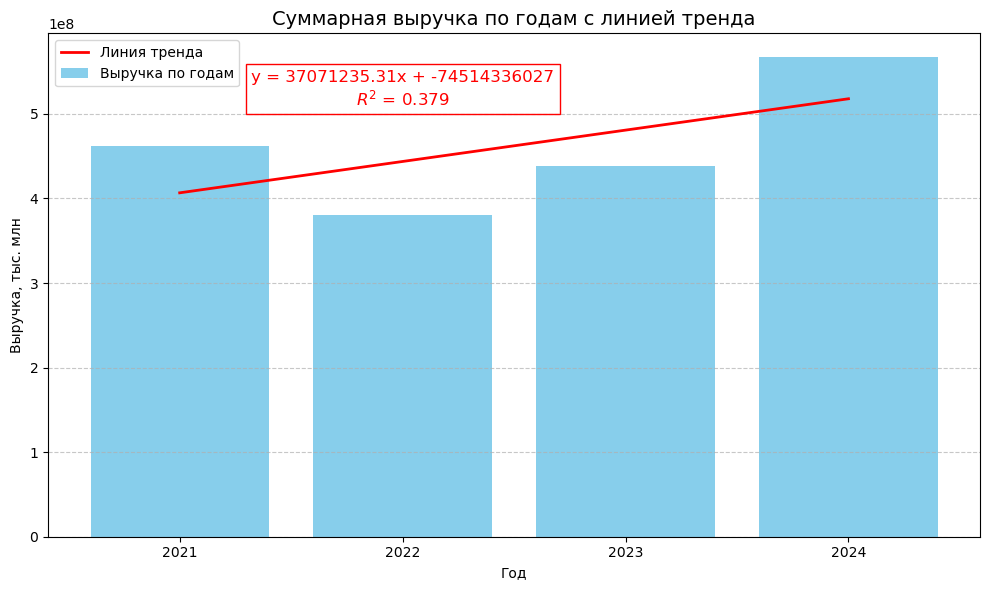

In [96]:
df_filtered = df_final[df_final['Год'] < 2025]

# Группировка по годам
yearly_expense = df_filtered.groupby('Год')['Выручка'].sum().reset_index()

# Подготовка данных
x = yearly_expense['Год'].values
y = yearly_expense['Выручка'].values

# Расчёт уравнения тренда
z = np.polyfit(x, y, 1)
p = np.poly1d(z)
y_pred = p(x)
r2 = np.corrcoef(y, y_pred)[0, 1] ** 2

# Построение графика
plt.figure(figsize=(10, 6))
plt.bar(x, y, color='skyblue', label='Выручка по годам')
plt.plot(x, y_pred, color='red', linewidth=2, label='Линия тренда')

# Добавим уравнение и R²
equation_text = f'y = {z[0]:.2f}x + {z[1]:.0f}\n$R^2$ = {r2:.3f}'
plt.text(
    x[len(x) // 3],               # Примерно центр по оси X
    max(y) * 0.9,                 # Чуть ниже максимального значения по Y
    equation_text,
    fontsize=12,
    color='red',
    ha='center',                  # Горизонтальное выравнивание по центру
    bbox=dict(facecolor='none', edgecolor='red')  # Прозрачный фон и красная рамка
)
plt.title('Суммарная выручка по годам с линией тренда', fontsize=14)
plt.xlabel('Год')
plt.ylabel('Выручка, тыс. млн')
plt.xticks(x)  # чтобы годы отображались корректно
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

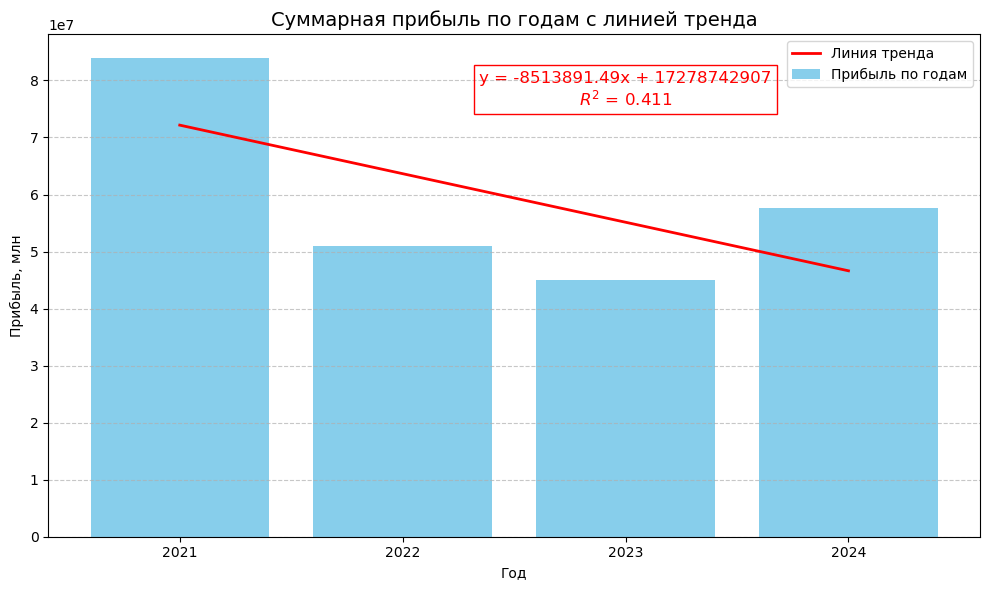

In [116]:
df_filtered = df_final[df_final['Год'] < 2025]

# Группировка по годам
yearly_expense = df_filtered.groupby('Год')['МП'].sum().reset_index()

# Подготовка данных
x = yearly_expense['Год'].values
y = yearly_expense['МП'].values

# Расчёт уравнения тренда
z = np.polyfit(x, y, 1)
p = np.poly1d(z)
y_pred = p(x)
r2 = np.corrcoef(y, y_pred)[0, 1] ** 2

# Построение графика
plt.figure(figsize=(10, 6))
plt.bar(x, y, color='skyblue', label='Прибыль по годам')
plt.plot(x, y_pred, color='red', linewidth=2, label='Линия тренда')

# Добавим уравнение и R²
equation_text = f'y = {z[0]:.2f}x + {z[1]:.0f}\n$R^2$ = {r2:.3f}'
plt.text(
    x[len(x) // 2],               # Примерно центр по оси X
    max(y) * 0.9,                 # Чуть ниже максимального значения по Y
    equation_text,
    fontsize=12,
    color='red',
    ha='center',                  # Горизонтальное выравнивание по центру
    bbox=dict(facecolor='none', edgecolor='red')  # Прозрачный фон и красная рамка
)
plt.title('Суммарная прибыль по годам с линией тренда', fontsize=14)
plt.xlabel('Год')
plt.ylabel('Прибыль, млн')
plt.xticks(x)  # чтобы годы отображались корректно
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

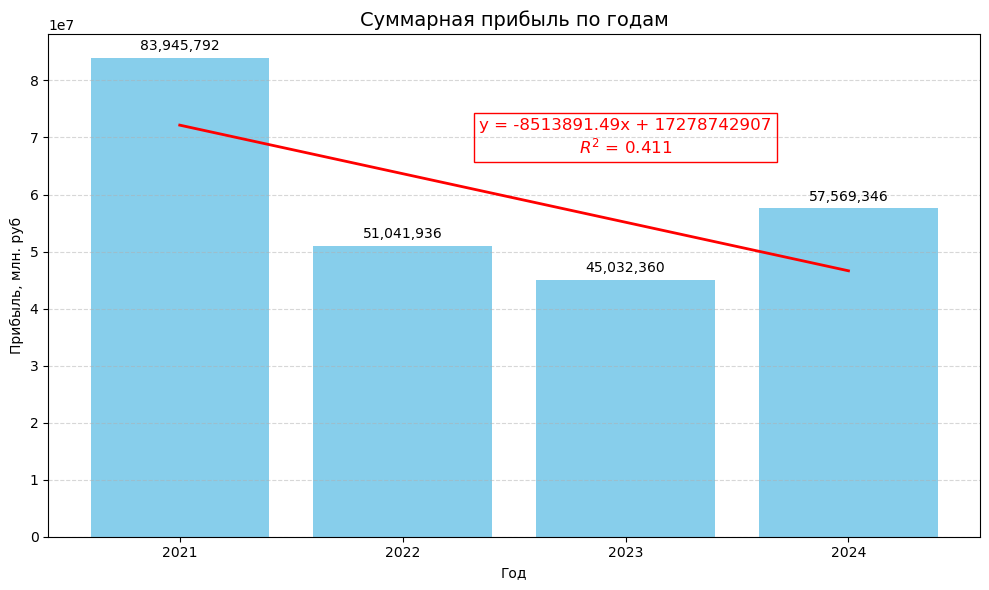

In [125]:
plt.figure(figsize=(10, 6))
plt.bar(x, y, color='skyblue', label='Прибыль')
plt.plot(x, y_pred, color='red', linewidth=2, label='Линия тренда')

# Подписи над столбцами
for i in range(len(x)):
    plt.text(x[i], y[i] + max(y) * 0.01, f'{y[i]:,.0f}',  # округляем до целого
             ha='center', va='bottom', fontsize=10)

# Добавим уравнение и R²
equation_text = f'y = {z[0]:.2f}x + {z[1]:.0f}\n$R^2$ = {r2:.3f}'
plt.text(
    x[len(x) // 2],
    max(y) * 0.8,
    equation_text,
    fontsize=12,
    color='red',
    ha='center',
    bbox=dict(facecolor='none', edgecolor='red')
)

plt.title('Суммарная прибыль по годам', fontsize=14)
plt.xlabel('Год')
plt.ylabel('Прибыль, млн. руб')
plt.xticks(x)
#plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
